# **1. Introdução**

## Contextualização do Projeto

O mercado de veículos usados apresenta uma ampla variedade de opções, preços e características, tornando a análise de dados uma ferramenta importante para compreender o comportamento desse segmento.

Este projeto tem como objetivo desenvolver uma análise exploratória de dados (*Exploratory Data Analysis — EDA*) a partir de um conjunto de anúncios de veículos usados nos Estados Unidos.

Por meio de técnicas de análise e visualização de dados, serão investigadas características dos veículos, padrões de preços e possíveis relações entre variáveis como ano de fabricação, quilometragem, condição, tipo de veículo e transmissão.

A proposta é transformar dados brutos em informações relevantes, identificando padrões e tendências que possam contribuir para uma melhor compreensão do mercado automotivo.

## Objetivos da Análise

- Investigar a estrutura e a qualidade do conjunto de dados.
- Realizar o tratamento de valores ausentes e inconsistências.
- Analisar a distribuição dos preços dos veículos.
- Identificar relações entre preço, quilometragem, ano de fabricação e condição.
- Comparar características e preços entre diferentes categorias de veículos.
- Desenvolver visualizações que facilitem a interpretação dos resultados.
- Extrair conclusões fundamentadas nos dados analisados.

## Ferramentas e Tecnologias

O projeto utilizará as seguintes tecnologias:

- **Python:** linguagem principal para análise e manipulação dos dados.
- **Pandas e NumPy:** tratamento, transformação e análise dos dados.
- **Matplotlib e Plotly:** criação de visualizações estáticas e interativas.
- **Streamlit:** desenvolvimento posterior de um dashboard interativo.

## Conjunto de Dados

A análise será realizada com o arquivo `vehicles.csv`, composto por anúncios de veículos usados e informações como preço, fabricante/modelo, ano de fabricação, quilometragem, condição, combustível, transmissão e data de publicação.

## Abordagem Metodológica

O desenvolvimento será dividido em etapas:

1. Inspeção inicial e compreensão dos dados.
2. Avaliação da qualidade e tratamento dos dados.
3. Análise exploratória e estatística descritiva.
4. Investigação de relações entre variáveis.
5. Visualização e interpretação dos resultados.
6. Desenvolvimento de um dashboard interativo para apresentação dos principais insights.

# **2. Carregamento e Compreensão dos Dados**

Nesta etapa, será realizado o carregamento do conjunto de dados `vehicles.csv` utilizando a biblioteca Pandas.

O objetivo é compreender a estrutura do dataset, identificar as variáveis disponíveis, verificar os tipos de dados e avaliar suas características iniciais.

Essa inspeção permitirá conhecer a composição dos dados e estabelecer uma base para as próximas etapas de análise exploratória e preparação dos dados.

In [1]:
# Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

# Carregamento dos dados
df = pd.read_csv('/content/vehicles.csv')

# Configuração de visualização
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Primeira visualização
display(df.head(10))

print(f"Quantidade de registros: {df.shape[0]:,}")
print(f"Quantidade de variáveis: {df.shape[1]}")

,price,model_year,model,condition,cylinders,fuel,odometer,transmission,type,paint_color,is_4wd,date_posted,days_listed
0,9400,"2,011.00",bmw x5,good,6.00,gas,"145,000.00",automatic,SUV,NaN,1.00,2018-06-23,19
1,25500,NaN,ford f-150,good,6.00,gas,"88,705.00",automatic,pickup,white,1.00,2018-10-19,50
2,5500,"2,013.00",hyundai sonata,like new,4.00,gas,"110,000.00",automatic,sedan,red,NaN,2019-02-07,79
3,1500,"2,003.00",ford f-150,fair,8.00,gas,NaN,automatic,pickup,NaN,NaN,2019-03-22,9
4,14900,"2,017.00",chrysler 200,excellent,4.00,gas,"80,903.00",automatic,sedan,black,NaN,2019-04-02,28
5,14990,"2,014.00",chrysler 300,excellent,6.00,gas,"57,954.00",automatic,sedan,black,1.00,2018-06-20,15
6,12990,"2,015.00",toyota camry,excellent,4.00,gas,"79,212.00",automatic,sedan,white,NaN,2018-12-27,73
7,15990,"2,013.00",honda pilot,excellent,6.00,gas,"109,473.00",automatic,SUV,black,1.00,2019-01-07,68
8,11500,"2,012.00",kia sorento,excellent,4.00,gas,"104,174.00",automatic,SUV,NaN,1.00,2018-07-16,19
9,9200,"2,008.00",honda pilot,excellent,NaN,gas,"147,191.00",automatic,SUV,blue,1.00,2019-02-15,17


Quantidade de registros: 51,525
Quantidade de variáveis: 13


### **2.1 — Inspeção da estrutura e qualidade dos dados**

In [2]:
# Informações gerais do dataset
df.info()

# Estatísticas descritivas das variáveis numéricas
display(df.describe().T)

# Quantidade de valores ausentes por variável
missing_data = pd.DataFrame({
    'Valores ausentes': df.isna().sum(),
    'Percentual (%)': (df.isna().mean() * 100).round(2)
})

display(missing_data.sort_values(
    by='Percentual (%)',
    ascending=False
))

# Verificar registros duplicados
print("Registros duplicados:", df.duplicated().sum())

# Verificar tipos de dados
display(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51525 entries, 0 to 51524
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   price         51525 non-null  int64  
 1   model_year    47906 non-null  float64
 2   model         51525 non-null  object 
 3   condition     51525 non-null  object 
 4   cylinders     46265 non-null  float64
 5   fuel          51525 non-null  object 
 6   odometer      43633 non-null  float64
 7   transmission  51525 non-null  object 
 8   type          51525 non-null  object 
 9   paint_color   42258 non-null  object 
 10  is_4wd        25572 non-null  float64
 11  date_posted   51525 non-null  object 
 12  days_listed   51525 non-null  int64  
dtypes: float64(4), int64(2), object(7)
memory usage: 5.1+ MB


,count,mean,std,min,25%,50%,75%,max
price,"51,525.00","12,132.46","10,040.80",1.00,"5,000.00","9,000.00","16,839.00","375,000.00"
model_year,"47,906.00","2,009.75",6.28,"1,908.00","2,006.00","2,011.00","2,014.00","2,019.00"
cylinders,"46,265.00",6.13,1.66,3.00,4.00,6.00,8.00,12.00
odometer,"43,633.00","115,553.46","65,094.61",0.00,"70,000.00","113,000.00","155,000.00","990,000.00"
is_4wd,"25,572.00",1.00,0.00,1.00,1.00,1.00,1.00,1.00
days_listed,"51,525.00",39.55,28.20,0.00,19.00,33.00,53.00,271.00


,Valores ausentes,Percentual (%)
is_4wd,25953,50.37
paint_color,9267,17.99
odometer,7892,15.32
cylinders,5260,10.21
model_year,3619,7.02
condition,0,0.00
model,0,0.00
price,0,0.00
fuel,0,0.00
type,0,0.00


Registros duplicados: 0


,0
price,int64
model_year,float64
model,object
condition,object
cylinders,float64
fuel,object
odometer,float64
transmission,object
type,object
paint_color,object


**Interpretação dos Resultados**

O conjunto de dados contém 51.525 registros e 13 variáveis, sem registros duplicados. Foram identificados valores ausentes em cinco colunas, com maior concentração em `is_4wd` (50,37%), seguida de `paint_color` (17,99%) e `odometer` (15,32%).

Também foram identificadas diferenças nos tipos de dados que poderão exigir conversão, especialmente nas variáveis de ano, cilindros e data de publicação.

Os resultados indicam a necessidade de investigar os valores ausentes, possíveis inconsistências e valores extremos antes de iniciar o tratamento e a análise exploratória.

### **2.2 — Investigação das variáveis e possíveis inconsistências**

In [3]:
# Verificar categorias e frequências
categorical_columns = [
    'model', 'condition', 'fuel',
    'transmission', 'type', 'paint_color'
]

for column in categorical_columns:
    print(f'\n--- {column.upper()} ---')
    print(df[column].value_counts(dropna=False).head(15))


# Verificar valores únicos das variáveis específicas
print("\nValores de is_4wd:")
print(df['is_4wd'].value_counts(dropna=False))

print("\nValores de condition:")
print(df['condition'].value_counts(dropna=False))


# Verificar extremos das variáveis numéricas
numeric_columns = [
    'price', 'model_year', 'cylinders',
    'odometer', 'days_listed'
]

display(df[numeric_columns].agg([
    'min', 'median', 'mean', 'max'
]).T)


# Verificar período dos anúncios
print("\nPeríodo dos anúncios:")
print("Data inicial:", df['date_posted'].min())
print("Data final:", df['date_posted'].max())


--- MODEL ---
model
ford f-150                    2796
chevrolet silverado 1500      2171
ram 1500                      1750
chevrolet silverado           1271
jeep wrangler                 1119
ram 2500                      1091
toyota camry                   990
honda accord                   964
chevrolet silverado 2500hd     915
gmc sierra 1500                906
ford explorer                  847
ford escape                    841
toyota tacoma                  827
honda civic                    815
nissan altima                  813
Name: count, dtype: int64

--- CONDITION ---
condition
excellent    24773
good         20145
like new      4742
fair          1607
new            143
salvage        115
Name: count, dtype: int64

--- FUEL ---
fuel
gas         47288
diesel       3714
hybrid        409
other         108
electric        6
Name: count, dtype: int64

--- TRANSMISSION ---
transmission
automatic    46902
manual        2829
other         1794
Name: count, dtype: int64

--- T

,min,median,mean,max
price,1.00,"9,000.00","12,132.46","375,000.00"
model_year,"1,908.00","2,011.00","2,009.75","2,019.00"
cylinders,3.00,6.00,6.13,12.00
odometer,0.00,"113,000.00","115,553.46","990,000.00"
days_listed,0.00,33.00,39.55,271.00



Período dos anúncios:
Data inicial: 2018-05-01
Data final: 2019-04-19


**Interpretação das Categorias e Valores Extremos**

A análise identificou predominância de veículos das marcas e modelos mais populares, com destaque para o Ford F-150. A maioria dos anúncios corresponde a veículos em condições *excellent* e *good*, com combustível a gasolina e transmissão automática.

SUVs, trucks e sedans representam as categorias de veículos mais frequentes. Também foram observados valores extremos de preço e quilometragem, que deverão ser investigados antes da análise estatística.

O conjunto de dados abrange anúncios publicados entre maio de 2018 e abril de 2019, oferecendo uma base para investigar características e padrões do mercado de veículos usados.

### **2.3 — Investigação dos valores ausentes**

In [4]:
# Identificar registros com valores ausentes
missing_rows = df[df.isna().any(axis=1)].copy()

print("Registros com pelo menos um valor ausente:",
      len(missing_rows))

print("Percentual do dataset:",
      round(len(missing_rows) / len(df) * 100, 2), "%")


# Verificar quantidade de ausências por registro
missing_rows_count = df.isna().sum(axis=1).value_counts().sort_index()

display(
    missing_rows_count.to_frame(
        name='Quantidade de registros'
    )
)


# Analisar valores ausentes por modelo
for column in ['model_year', 'cylinders', 'odometer']:
    print(f"\nAusências em {column} por modelo:")

    display(
        df.groupby('model')[column]
        .apply(lambda x: x.isna().sum())
        .sort_values(ascending=False)
        .head(10)
    )

Registros com pelo menos um valor ausente: 36673
Percentual do dataset: 71.18 %


,Quantidade de registros
0,14852
1,23771
2,10674
3,2044
4,180
5,4



Ausências em model_year por modelo:


,model_year
model,
ford f-150,191
chevrolet silverado 1500,155
ram 1500,117
chevrolet silverado,98
honda accord,80
ram 2500,80
jeep wrangler,70
jeep grand cherokee,68
ford escape,68



Ausências em cylinders por modelo:


,cylinders
model,
ford f-150,316
chevrolet silverado 1500,231
ram 1500,185
chevrolet silverado,137
ram 2500,122
jeep wrangler,112
toyota tacoma,97
honda civic,95
ford focus,93



Ausências em odometer por modelo:


,odometer
model,
ford f-150,419
chevrolet silverado 1500,322
ram 1500,279
chevrolet silverado,192
ram 2500,181
jeep wrangler,177
ford escape,156
honda accord,143
chevrolet silverado 2500hd,139


**Interpretação da Investigação dos Valores Ausentes**

A investigação identificou que 71,18% dos registros apresentam pelo menos um valor ausente. A maior parte possui uma ou duas informações não preenchidas.

As variáveis `model_year`, `cylinders` e `odometer` apresentam ausências recorrentes em modelos populares, indicando a necessidade de avaliar sua distribuição antes de definir o método de preenchimento.

Diante desse cenário, o tratamento deverá considerar as características de cada variável, buscando preservar o maior número possível de registros e evitar distorções nas análises posteriores.

### **2.4 — Análise da proporção de valores ausentes por modelo**

In [5]:
# Analisar a proporção de valores ausentes por modelo

columns_to_check = [
    'model_year',
    'cylinders',
    'odometer'
]

for column in columns_to_check:

    analysis = df.groupby('model').agg(
        total_records=('model', 'size'),
        missing_values=(column, lambda x: x.isna().sum())
    )

    analysis['missing_percentage'] = (
        analysis['missing_values'] /
        analysis['total_records'] * 100
    ).round(2)

    print(f'\nProporção de ausências em {column}:')

    display(
        analysis.sort_values(
            'missing_percentage',
            ascending=False
        ).head(10)
    )


Proporção de ausências em model_year:


,total_records,missing_values,missing_percentage
model,,,
mercedes-benz benze sprinter 2500,41,7,17.07
gmc yukon,331,39,11.78
jeep grand cherokee laredo,256,25,9.77
toyota camry le,316,29,9.18
ford f-250 super duty,241,22,9.13
toyota rav4,461,42,9.11
nissan maxima,294,26,8.84
toyota 4runner,453,39,8.61
ford expedition,372,32,8.60



Proporção de ausências em cylinders:


,total_records,missing_values,missing_percentage
model,,,
mercedes-benz benze sprinter 2500,41,7,17.07
nissan murano,235,33,14.04
subaru impreza,250,35,14.00
jeep grand cherokee laredo,256,34,13.28
kia soul,349,46,13.18
ford f-250,422,54,12.80
ford focus,754,93,12.33
nissan frontier,281,34,12.10
ford mustang gt coupe 2d,301,36,11.96



Proporção de ausências em odometer:


,total_records,missing_values,missing_percentage
model,,,
mercedes-benz benze sprinter 2500,41,41,100.00
kia sorento,236,45,19.07
nissan maxima,294,56,19.05
nissan versa,274,52,18.98
ford escape,841,156,18.55
ford ranger,423,77,18.20
nissan frontier,281,51,18.15
hyundai sonata,477,85,17.82
cadillac escalade,322,57,17.70


**Interpretação**

A análise da proporção de valores ausentes por modelo identificou diferenças na distribuição das informações faltantes. O destaque foi a variável `odometer`, em que o modelo `mercedes-benz benze sprinter 2500` apresentou ausência de quilometragem em todos os seus 41 registros.

Nas variáveis `model_year` e `cylinders`, os percentuais de ausência foram menores e distribuídos entre diferentes modelos.

Esses resultados indicam que o tratamento dos valores ausentes deve considerar as características de cada variável. Em especial, será necessário avaliar se é adequado preencher os dados de quilometragem ou preservar determinadas observações sem essa informação.

### **2.5. Visualização da distribuição das variáveis numéricas**

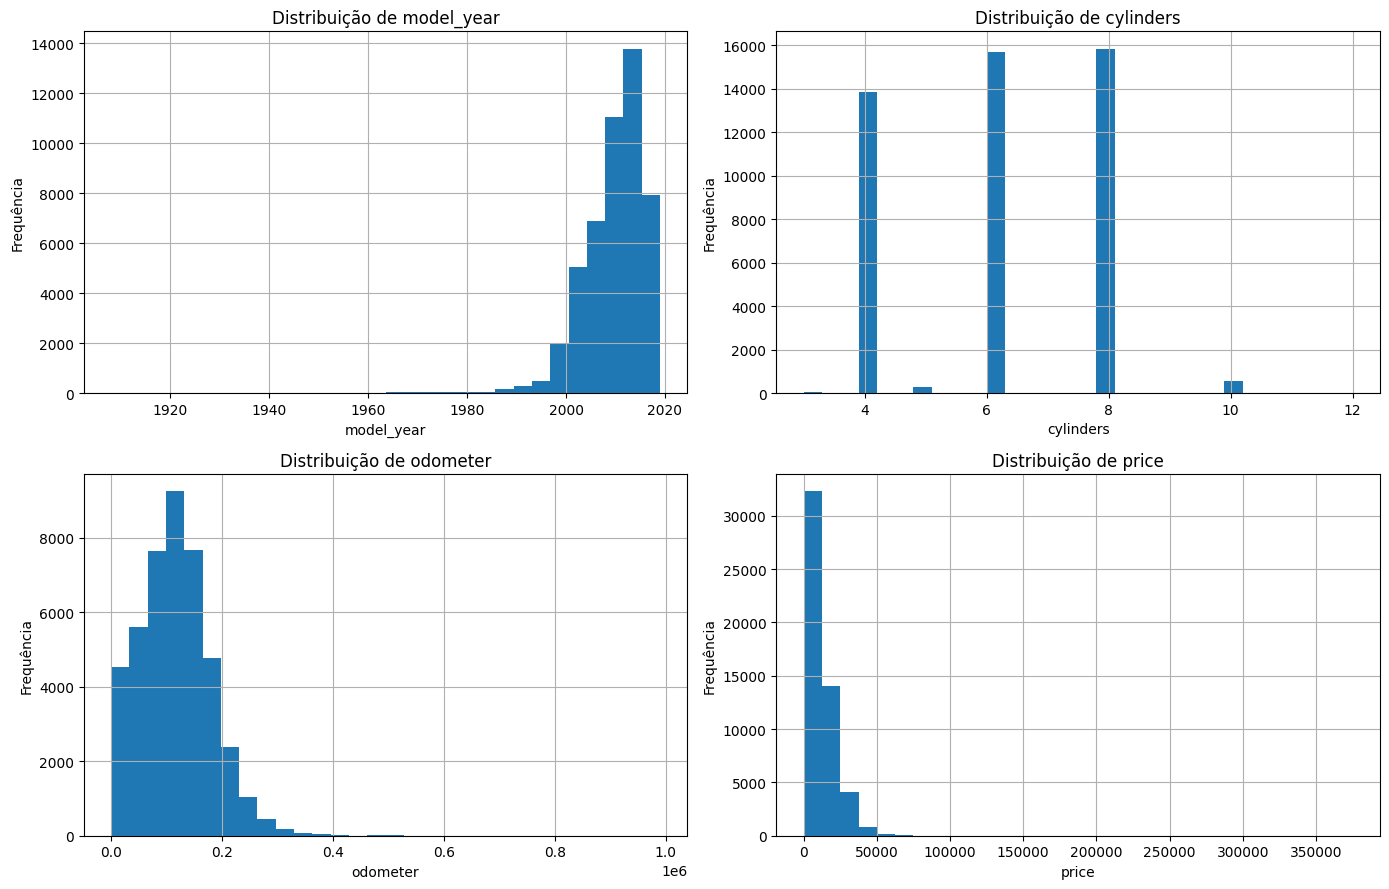

In [6]:
# Distribuição das variáveis numéricas
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

columns = ['model_year', 'cylinders', 'odometer', 'price']

for column, ax in zip(columns, axes.flatten()):
    df[column].hist(bins=30, ax=ax)
    ax.set_title(f'Distribuição de {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Frequência')

plt.tight_layout()
plt.show()

**Interpretação das distribuições**

A visualização das variáveis numéricas revelou diferentes padrões de distribuição.

A variável `model_year` apresenta maior concentração de veículos fabricados entre 2000 e 2018, enquanto os anos mais antigos possuem baixa frequência.

A variável `cylinders` apresenta distribuição discreta, com predominância de veículos com 4, 6 e 8 cilindros.

As variáveis `odometer` e `price` apresentam assimetria à direita, indicando concentração de registros em valores menores e presença de observações com valores significativamente elevados.

Esses resultados mostram a necessidade de investigar possíveis valores extremos e inconsistências antes de realizar análises estatísticas e definir o tratamento dos dados ausentes.

### **2.6 — Análise dos percentis e investigação de valores extremos (outliers)**

In [7]:
# Análise dos percentis das variáveis numéricas

columns_to_analyze = ['price', 'model_year', 'cylinders', 'odometer', 'days_listed']

percentiles = df[columns_to_analyze].quantile(
    [0.00, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1.00]
)

display(percentiles.T)

,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
price,1.00,1.00,"1,950.00","5,000.00","9,000.00","16,839.00","30,300.00","43,995.00","375,000.00"
model_year,"1,908.00","1,990.00","1,999.00","2,006.00","2,011.00","2,014.00","2,018.00","2,018.00","2,019.00"
cylinders,3.00,4.00,4.00,4.00,6.00,8.00,8.00,10.00,12.00
odometer,0.00,117.00,"16,320.20","70,000.00","113,000.00","155,000.00","223,297.00","286,800.00","990,000.00"
days_listed,0.00,3.00,7.00,19.00,33.00,53.00,94.00,132.00,271.00


**Interpretação dos percentis**

A análise dos percentis identificou possíveis valores extremos em algumas variáveis numéricas.

Na variável `price`, observa-se que 99% dos registros apresentam valores de até US$ 43.995, enquanto o valor máximo chega a US$ 375.000.

Na variável `odometer`, 99% dos veículos possuem quilometragem de até 286.800 milhas, mas existem registros que chegam a 990.000 milhas.

A variável `model_year` apresenta registros desde 1908, enquanto `days_listed` possui anúncios com até 271 dias de publicação.

Já a variável `cylinders` apresenta valores discretos entre 3 e 12, compatíveis com diferentes configurações de motores.

Esses resultados indicam a necessidade de investigar os valores extremos antes de definir qualquer tratamento. Valores atípicos não devem ser removidos automaticamente, pois podem representar situações reais do mercado.

### **2.7. Investigação de possíveis outliers**

In [8]:
# Identificação de possíveis outliers pelo método IQR

columns_to_check = ['price', 'model_year', 'odometer', 'days_listed']

for column in columns_to_check:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(f'\nVariável: {column}')
    print(f'Limite inferior: {lower_limit:,.2f}')
    print(f'Limite superior: {upper_limit:,.2f}')
    print(f'Quantidade de possíveis outliers: {len(outliers):,}')
    print(f'Percentual: {len(outliers) / len(df) * 100:.2f}%')


Variável: price
Limite inferior: -12,758.50
Limite superior: 34,597.50
Quantidade de possíveis outliers: 1,646
Percentual: 3.19%

Variável: model_year
Limite inferior: 1,994.00
Limite superior: 2,026.00
Quantidade de possíveis outliers: 709
Percentual: 1.38%

Variável: odometer
Limite inferior: -57,500.00
Limite superior: 282,500.00
Quantidade de possíveis outliers: 487
Percentual: 0.95%

Variável: days_listed
Limite inferior: -32.00
Limite superior: 104.00
Quantidade de possíveis outliers: 1,618
Percentual: 3.14%


**Interpretação dos possíveis outliers**

A aplicação do método do intervalo interquartil (IQR) identificou possíveis valores extremos em quatro variáveis numéricas.

As variáveis `price` e `days_listed` apresentaram as maiores proporções de possíveis outliers, com 3,19% e 3,14%, respectivamente. Já `model_year` apresentou 1,38%, enquanto `odometer` apresentou 0,95%.

Os resultados indicam a presença de observações que se distanciam dos padrões centrais das distribuições. Entretanto, esses valores não representam necessariamente erros, podendo corresponder a características legítimas dos anúncios.

Por esse motivo, os registros serão investigados antes de qualquer decisão de remoção ou correção, preservando a representatividade do conjunto de dados.

### **2.8 — Investigar os registros extremos**

In [9]:
# Investigação dos maiores valores das variáveis

columns_to_check = ['price', 'model_year', 'odometer', 'days_listed']

for column in columns_to_check:
    print(f'\n--- MAIORES VALORES DE {column.upper()} ---')
    display(
        df.nlargest(10, column)[
            ['price', 'model_year', 'model', 'condition',
             'odometer', 'days_listed']
        ]
    )


--- MAIORES VALORES DE PRICE ---


,price,model_year,model,condition,odometer,days_listed
12504,375000,"1,999.00",nissan frontier,good,"115,000.00",21
11359,300000,"2,015.00",ram 2500,excellent,NaN,39
1309,189000,"2,014.00",ford f-150,good,"151,248.00",56
1668,189000,"2,014.00",ford f-150,good,"151,248.00",21
27375,189000,"2,014.00",ford f-150,good,"151,248.00",72
30634,189000,"2,014.00",ford f-150,good,NaN,42
33434,189000,"2,014.00",ford f-150,good,"151,248.00",102
34389,189000,"2,014.00",ford f-150,good,"151,248.00",28
34206,175000,"2,004.00",gmc sierra 2500hd,good,"149,000.00",57
41748,145000,"2,008.00",toyota tundra,like new,"140,000.00",29



--- MAIORES VALORES DE MODEL_YEAR ---


,price,model_year,model,condition,odometer,days_listed
78,23800,"2,019.00",nissan frontier crew cab sv,good,"10,899.00",30
106,21500,"2,019.00",nissan frontier crew cab sv,good,"16,168.00",70
112,22500,"2,019.00",nissan frontier crew cab sv,good,"24,209.00",73
125,22900,"2,019.00",nissan frontier crew cab sv,good,NaN,67
464,24200,"2,019.00",chevrolet camaro lt coupe 2d,good,"11,438.00",39
619,18900,"2,019.00",toyota camry le,like new,"13,355.00",55
833,44505,"2,019.00",dodge charger,new,202.00,44
843,22300,"2,019.00",nissan frontier crew cab sv,good,NaN,32
1446,14950,"2,019.00",toyota corolla,excellent,"34,929.00",65
1549,47500,"2,019.00",chevrolet suburban,excellent,"18,136.00",24



--- MAIORES VALORES DE ODOMETER ---


,price,model_year,model,condition,odometer,days_listed
17869,59900,"1,964.00",chevrolet corvette,like new,"990,000.00",28
40729,4700,"2,013.00",chevrolet cruze,good,"990,000.00",4
48962,40000,"2,014.00",ram 3500,excellent,"980,000.00",7
14245,6000,"1,996.00",ram 2500,good,"920,000.00",43
2840,18500,"2,014.00",ford explorer,excellent,"866,000.00",14
2440,5300,"2,010.00",toyota corolla,excellent,"840,000.00",13
32973,5550,"2,010.00",toyota corolla,excellent,"840,000.00",20
13027,8500,"2,015.00",chevrolet malibu,excellent,"838,095.00",10
41699,10300,"2,013.00",ford escape,excellent,"831,000.00",30
5735,7500,"2,015.00",hyundai elantra,excellent,"813,542.00",5



--- MAIORES VALORES DE DAYS_LISTED ---


,price,model_year,model,condition,odometer,days_listed
4360,5200,"2,011.00",chevrolet impala,like new,"122,000.00",271
28756,5500,"2,011.00",nissan versa,excellent,"96,000.00",267
2224,5995,"2,004.00",ford f-250,good,"103,000.00",263
51,3800,"2,012.00",ford focus,good,"130,323.00",261
7875,8980,NaN,nissan altima,excellent,"101,611.00",256
46583,11500,"2,017.00",ford fusion,excellent,"65,000.00",252
3202,5995,"2,009.00",toyota prius,excellent,"130,000.00",244
24527,5995,"2,007.00",toyota rav4,good,"106,000.00",243
19763,31995,"2,015.00",jeep wrangler unlimited,excellent,NaN,240
11698,21995,"2,019.00",chevrolet impala,like new,NaN,236


**Interpretação dos registros extremos**

A investigação dos maiores valores identificou possíveis inconsistências e observações que merecem atenção.

Na variável `price`, foi identificado um anúncio de 375.000 para uma Nissan Frontier 1999. Também foram observados registros repetidos de uma Ford F-150 2014 com preço de US$ 189.000, indicando a necessidade de investigar possíveis duplicidades.

Na variável `model_year`, os registros mais recentes correspondem a veículos de 2019, sem indícios evidentes de inconsistência.

Na variável `odometer`, foram encontrados valores próximos de 1 milhão de milhas, que podem representar erros de preenchimento ou situações excepcionais.

Já na variável `days_listed`, os maiores períodos de publicação chegaram a 271 dias. Esses registros serão preservados até que existam evidências de inconsistência.

A análise demonstra que os valores extremos devem ser avaliados individualmente, considerando o contexto de cada variável, antes de qualquer remoção ou correção.

### **2.9 — Investigar possíveis registros duplicados**

In [10]:
# Investigar possíveis duplicidades da Ford F-150

ford_outliers = df[
    (df['model'] == 'ford f-150') &
    (df['price'] == 189000)
]

display(ford_outliers)

print("Quantidade de registros:", len(ford_outliers))
print("Registros totalmente duplicados:", ford_outliers.duplicated().sum())

,price,model_year,model,condition,cylinders,fuel,odometer,transmission,type,paint_color,is_4wd,date_posted,days_listed
1309,189000,"2,014.00",ford f-150,good,6.00,gas,"151,248.00",automatic,truck,black,NaN,2019-03-02,56
1668,189000,"2,014.00",ford f-150,good,6.00,gas,"151,248.00",automatic,truck,NaN,NaN,2019-03-20,21
27375,189000,"2,014.00",ford f-150,good,6.00,gas,"151,248.00",automatic,truck,black,NaN,2018-09-25,72
30634,189000,"2,014.00",ford f-150,good,6.00,gas,NaN,automatic,truck,black,NaN,2018-07-21,42
33434,189000,"2,014.00",ford f-150,good,6.00,gas,"151,248.00",automatic,truck,black,NaN,2019-02-05,102
34389,189000,"2,014.00",ford f-150,good,6.00,gas,"151,248.00",automatic,truck,black,NaN,2019-02-02,28


Quantidade de registros: 6
Registros totalmente duplicados: 0


**Interpretação da investigação de duplicidades**

A investigação identificou seis registros referentes ao modelo Ford F-150, ano 2014, todos com preço de US$ 189.000.

Apesar das semelhanças entre as características dos veículos, os registros apresentam diferentes datas de publicação e pequenas diferenças em algumas informações, como quilometragem e cor.

A verificação também confirmou que não existem duplicatas completas entre esses seis registros.

Dessa forma, os anúncios serão mantidos na base, pois não há evidências suficientes para classificá-los como duplicados.

### **2.10 — Verificação de inconsistências nos dados**

In [11]:
# Verificação de valores inválidos

print("Preços iguais ou inferiores a zero:",
      (df['price'] <= 0).sum())

print("Anos anteriores a 1900:",
      (df['model_year'] < 1900).sum())

print("Anos posteriores a 2019:",
      (df['model_year'] > 2019).sum())

print("Quilometragens negativas:",
      (df['odometer'] < 0).sum())

print("Dias de anúncio negativos:",
      (df['days_listed'] < 0).sum())

print("Número de cilindros fora do intervalo de 3 a 12:",
      (~df['cylinders'].between(3, 12)).sum())

Preços iguais ou inferiores a zero: 0
Anos anteriores a 1900: 0
Anos posteriores a 2019: 0
Quilometragens negativas: 0
Dias de anúncio negativos: 0
Número de cilindros fora do intervalo de 3 a 12: 5260


In [12]:
# Verificar valores inválidos em cylinders, excluindo ausências

invalid_cylinders = df[
    df['cylinders'].notna() &
    ~df['cylinders'].between(3, 12)
]

print("Valores de cylinders fora do intervalo de 3 a 12:",
      len(invalid_cylinders))

display(invalid_cylinders['cylinders'].value_counts())

Valores de cylinders fora do intervalo de 3 a 12: 0


,count
cylinders,


**Interpretação da verificação de inconsistências**

Após corrigir a verificação da variável `cylinders`, excluindo os valores ausentes da análise, foi confirmado que não existem registros com número de cilindros fora do intervalo estabelecido entre 3 e 12.

As demais verificações também não identificaram valores inválidos em preço, ano do modelo, quilometragem ou dias de anúncio.

Dessa forma, não foram encontradas inconsistências numéricas evidentes nos critérios avaliados. Entretanto, os valores extremos identificados anteriormente ainda precisam ser considerados durante a preparação dos dados.

# **3. Preparação e tratamento dos dados**

Nesta etapa, será realizada a preparação do conjunto de dados para garantir maior consistência e confiabilidade nas análises exploratórias.

Após a investigação inicial, serão avaliados os tipos de dados, os valores ausentes e as possíveis inconsistências identificadas nas variáveis.

O tratamento será conduzido considerando as características de cada variável, buscando preservar a representatividade dos registros e evitar distorções nos resultados.

**Objetivos desta etapa:**
- Adequar os tipos de dados, quando necessário.
- Avaliar e tratar os valores ausentes.
- Verificar e corrigir possíveis inconsistências.
- Reavaliar a qualidade e a integridade da base após o tratamento.

Ao final, será obtido um conjunto de dados preparado para as análises exploratórias e visualizações posteriores.

In [13]:
# Conversão da coluna date_posted para datetime

df['date_posted'] = pd.to_datetime(df['date_posted'])

# Verificação dos tipos de dados
display(df.dtypes)

,0
price,int64
model_year,float64
model,object
condition,object
cylinders,float64
fuel,object
odometer,float64
transmission,object
type,object
paint_color,object


**Conversão e adequação dos tipos de dados**

Foi realizada a conversão da variável `date_posted` para o formato `datetime64[ns]`, permitindo operações e análises temporais.

A avaliação dos tipos de dados também identificou variáveis numéricas armazenadas como ponto flutuante (`float64`), embora representem informações inteiras, como `model_year`, `cylinders` e `is_4wd`.

A conversão dessas variáveis será considerada após o tratamento dos valores ausentes, evitando problemas durante a transformação dos dados.

As demais variáveis apresentam tipos compatíveis com suas características e serão mantidas neste momento.

### **3.1 — Tratamento dos valores ausentes**

In [14]:
# Resumo dos valores ausentes

missing_summary = pd.DataFrame({
    'Valores ausentes': df.isna().sum(),
    'Percentual (%)': (df.isna().mean() * 100).round(2)
})

display(
    missing_summary[missing_summary['Valores ausentes'] > 0]
    .sort_values('Percentual (%)', ascending=False)
)

,Valores ausentes,Percentual (%)
is_4wd,25953,50.37
paint_color,9267,17.99
odometer,7892,15.32
cylinders,5260,10.21
model_year,3619,7.02


**Interpretação**

A análise identificou valores ausentes em cinco variáveis do conjunto de dados, com diferentes proporções de ocorrência.

A variável `is_4wd` apresenta a maior quantidade de informações faltantes, seguida por `paint_color`, `odometer`, `cylinders` e `model_year`.

Devido às diferenças entre as características dessas variáveis, o tratamento será realizado individualmente. A estratégia deverá considerar o significado de cada informação e o impacto que seu preenchimento poderá causar nas análises posteriores.

### **3.2 — Investigação da variável is_4wd**

In [15]:
print("Distribuição de is_4wd:")
display(df['is_4wd'].value_counts(dropna=False))

print("\nDistribuição percentual:")
display(
    (df['is_4wd'].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Distribuição de is_4wd:


,count
is_4wd,
NaN,25953
1.00,25572



Distribuição percentual:


,proportion
is_4wd,
NaN,50.37
1.00,49.63


**Interpretação**

A análise da variável `is_4wd` revelou que os registros disponíveis apresentam apenas o valor 1, indicando veículos com tração nas quatro rodas, além de uma quantidade expressiva de valores ausentes.

Não foram identificados registros com valor 0. Dessa forma, não é possível determinar se os valores ausentes representam veículos sem tração nas quatro rodas ou informações que não foram preenchidas no momento do cadastro.

Considerando essa limitação, os valores ausentes não serão substituídos automaticamente por zero, evitando atribuir características não confirmadas aos veículos.

### **3.3 — Investigação dos valores ausentes em paint_color**

In [16]:
print("Distribuição de paint_color:")
display(df['paint_color'].value_counts(dropna=False))

print("\nDistribuição percentual:")
display(
    (df['paint_color'].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Distribuição de paint_color:


,count
paint_color,
white,10029
NaN,9267
black,7692
silver,6244
grey,5037
blue,4475
red,4421
green,1396
brown,1223



Distribuição percentual:


,proportion
paint_color,
white,19.46
NaN,17.99
black,14.93
silver,12.12
grey,9.78
blue,8.69
red,8.58
green,2.71
brown,2.37


**Interpretação**

A análise da variável `paint_color` identificou diferentes categorias de cores, com predominância de veículos brancos, pretos, prateados e cinza.

Também foi observada uma quantidade relevante de registros sem informação sobre a cor do veículo.

Embora a cor branca seja a categoria mais frequente, não será utilizada para preencher os valores ausentes, pois essa substituição poderia distorcer a distribuição original da variável.

Dessa forma, os valores ausentes serão mantidos, preservando a integridade das informações disponíveis.

### **3.4 — Investigação dos valores ausentes em odometer**

In [17]:
# Análise da quilometragem por estatísticas descritivas

display(df['odometer'].describe())

print("\nMediana por condição do veículo:")
display(
    df.groupby('condition')['odometer']
    .median()
    .sort_values(ascending=False)
)

,odometer
count,"43,633.00"
mean,"115,553.46"
std,"65,094.61"
min,0.00
25%,"70,000.00"
50%,"113,000.00"
75%,"155,000.00"
max,"990,000.00"



Mediana por condição do veículo:


,odometer
condition,
fair,"181,613.00"
salvage,"142,673.50"
good,"129,000.00"
excellent,"104,230.00"
like new,"72,982.50"
new,"8,002.00"


**Interpretação Odometer**

A análise da variável `odometer` revelou diferenças na quilometragem mediana entre as categorias de condição dos veículos.

Os veículos classificados como `fair` apresentaram a maior quilometragem mediana, enquanto aqueles classificados como `new` apresentaram a menor.

Esse comportamento indica uma relação entre a condição declarada do veículo e sua quilometragem.

Diante desse padrão, será utilizada a mediana agrupada por condição para preencher os valores ausentes de `odometer`. Essa estratégia considera as características dos grupos e evita aplicar um único valor de referência para todos os veículos.

In [18]:
# Criar cópia da base antes do tratamento
df_clean = df.copy()

# Preencher odometer pela mediana de cada condição
df_clean['odometer'] = df_clean['odometer'].fillna(
    df_clean.groupby('condition')['odometer'].transform('median')
)

# Verificar o resultado
print("Valores ausentes antes:", df['odometer'].isna().sum())
print("Valores ausentes depois:", df_clean['odometer'].isna().sum())

Valores ausentes antes: 7892
Valores ausentes depois: 0


O preenchimento da variável `odometer` foi realizado utilizando a mediana agrupada pela condição dos veículos (`condition`).

Essa estratégia considerou as diferenças de quilometragem entre as categorias de conservação, evitando a utilização de um único valor de referência para toda a base.

Após o procedimento, todos os valores ausentes dessa variável foram preenchidos, mantendo os registros originais e preservando a estrutura do conjunto de dados.

### **3.5 — Investigação dos valores ausentes em cylinders**

In [19]:
# Distribuição de cylinders, incluindo valores ausentes

print("Distribuição de cylinders:")
display(df['cylinders'].value_counts(dropna=False).sort_index())

print("\nDistribuição percentual:")
display(
    (df['cylinders'].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Distribuição de cylinders:


,count
cylinders,
3.00,34
4.00,13864
5.00,272
6.00,15700
8.00,15844
10.00,549
12.00,2
NaN,5260



Distribuição percentual:


,proportion
cylinders,
8.00,30.75
6.00,30.47
4.00,26.91
NaN,10.21
10.00,1.07
5.00,0.53
3.00,0.07
12.00,0.00


In [20]:
# Mediana de cilindros por tipo de veículo

display(
    df.groupby('type')['cylinders']
    .median()
    .sort_values()
)

# Mediana de cilindros por modelo
display(
    df.groupby('model')['cylinders']
    .median()
    .sort_values()
)

,cylinders
type,
hatchback,4.00
sedan,4.00
wagon,4.00
SUV,6.00
offroad,6.00
other,6.00
mini-van,6.00
coupe,6.00
van,6.00


,cylinders
model,
chevrolet equinox,4.00
chevrolet malibu,4.00
chevrolet cruze,4.00
chrysler 200,4.00
ford escape,4.00
...,...
ford expedition,8.00
gmc sierra,8.00
gmc sierra 1500,8.00


In [21]:
# Mediana de cilindros por tipo de veículo

display(
    df.groupby('type')['cylinders']
    .median()
    .sort_values()
)

,cylinders
type,
hatchback,4.00
sedan,4.00
wagon,4.00
SUV,6.00
offroad,6.00
other,6.00
mini-van,6.00
coupe,6.00
van,6.00


In [22]:
# Mediana de cilindros por modelo

display(
    df.groupby('model')['cylinders']
    .agg(['count', 'median'])
    .sort_values('median')
)

,count,median
model,,
chevrolet equinox,535,4.00
chevrolet malibu,547,4.00
chevrolet cruze,408,4.00
chrysler 200,219,4.00
ford escape,766,4.00
...,...,...
ford expedition,334,8.00
gmc sierra,361,8.00
gmc sierra 1500,822,8.00


**Interpretação: Mediana de cilindros por tipo e por modelo**

A análise da mediana de cilindros por tipo de veículo revelou diferenças entre as categorias, indicando uma relação entre o tipo de veículo e a configuração do motor.

Os veículos hatchback, sedan e wagon apresentam mediana de 4 cilindros. Já categorias como SUV, offroad, minivan, coupe e van apresentam mediana de 6 cilindros.

As categorias convertible, truck e pickup apresentam mediana de 8 cilindros, enquanto a categoria bus apresenta mediana de 10 cilindros.

A análise por modelo também demonstra diferenças nas configurações dos motores. Modelos como Chevrolet Equinox, Chevrolet Malibu e Ford Escape apresentam mediana de 4 cilindros, enquanto Ford Expedition, GMC Sierra e Toyota Tundra apresentam mediana de 8 cilindros.

Esses resultados demonstram que tanto o tipo quanto o modelo do veículo podem ajudar a compreender a distribuição da variável cylinders, sendo informações relevantes para definir uma estratégia de tratamento dos valores ausentes.

Observação: a tabela por modelo apresenta 100 modelos, mas a visualização enviada mostra apenas alguns exemplos. Portanto, a interpretação considera somente os resultados efetivamente apresentados.

### **3.6. Estratégia de preenchimento pela mediana por modelo**

In [23]:
# Verificar quantidade de registros disponíveis por modelo

model_cylinders = (
    df.groupby('model')['cylinders']
    .agg(['count', 'median'])
    .sort_values('count')
)

display(model_cylinders.head(20))

,count,median
model,,
mercedes-benz benze sprinter 2500,34,6.00
nissan murano,202,6.00
kia sorento,209,4.00
acura tl,211,6.00
subaru impreza,215,4.00
ford f-250 super duty,216,8.00
chrysler 200,219,4.00
chevrolet silverado 3500hd,221,8.00
ford f350,222,8.00


A análise da quantidade de registros disponíveis por modelo revelou que a maioria dos veículos possui volume suficiente de observações para calcular uma mediana de cilindros.

Foram identificadas diferenças entre os modelos, com medianas de 4, 6 e 8 cilindros, demonstrando que essa característica varia conforme o veículo.

Entretanto, alguns modelos apresentam menor quantidade de registros válidos, como o Mercedes-Benz Sprinter 2500, o que exige maior cautela na utilização da mediana individual.

Dessa forma, a mediana por modelo será considerada como estratégia principal de preenchimento, avaliando alternativas para os modelos com poucas observações disponíveis.

### **3.7. Aplicação e validação do preenchimento de cylinders**

In [24]:
# Preencher cylinders pela mediana do modelo
model_median = df_clean.groupby('model')['cylinders'].transform('median')

# Calcular a mediana por tipo de veículo
type_median = df_clean.groupby('type')['cylinders'].transform('median')

# Quantidade de registros válidos por modelo
model_count = df_clean.groupby('model')['cylinders'].transform('count')

# Aplicar a estratégia de preenchimento
df_clean['cylinders'] = df_clean['cylinders'].fillna(
    model_median.where(model_count >= 100, type_median)
)

# Verificar o resultado
print("Valores ausentes antes:", df['cylinders'].isna().sum())
print("Valores ausentes depois:", df_clean['cylinders'].isna().sum())

Valores ausentes antes: 5260
Valores ausentes depois: 0


**Interpretação**

A aplicação da estratégia de preenchimento foi realizada utilizando a mediana por modelo para os grupos com quantidade suficiente de observações válidas.

Para os modelos com menos registros disponíveis, foi utilizada a mediana por tipo de veículo, considerando essa informação como referência alternativa.

Após o procedimento, todos os valores ausentes da variável `cylinders` foram preenchidos, mantendo os registros e a estrutura do conjunto de dados.

### **3.8. Investigação dos valores ausentes em model_year**

In [25]:
# Estatísticas descritivas de model_year

display(df_clean['model_year'].describe())

print("\nMediana por modelo:")
display(
    df_clean.groupby('model')['model_year']
    .agg(['count', 'median'])
    .sort_values('count')
    .head(20)
)

,model_year
count,"47,906.00"
mean,"2,009.75"
std,6.28
min,"1,908.00"
25%,"2,006.00"
50%,"2,011.00"
75%,"2,014.00"
max,"2,019.00"



Mediana por modelo:


,count,median
model,,
mercedes-benz benze sprinter 2500,34,"2,013.00"
nissan murano,215,"2,009.00"
ford f-250 super duty,219,"2,008.00"
kia sorento,222,"2,013.00"
dodge dakota,224,"2,004.00"
acura tl,224,"2,007.00"
chrysler 200,224,"2,014.00"
ford f350 super duty,228,"2,006.50"
chevrolet silverado 3500hd,229,"2,013.00"


**Interpretação**

A análise da variável `model_year` revelou que os veículos estão concentrados principalmente entre os anos de 2006 e 2014, com mediana de 2011.

A investigação por modelo demonstrou diferenças nos anos de fabricação, indicando que essa característica pode ser considerada no tratamento dos valores ausentes.

A maioria dos modelos apresenta quantidade significativa de registros disponíveis, enquanto alguns possuem menor representatividade, exigindo cautela na utilização de suas medianas.

Dessa forma, a mediana por modelo será avaliada como estratégia de preenchimento, considerando alternativas para os modelos com poucas observações disponíveis.

### **3.9. Estratégia de preenchimento dos valores ausentes em model_year**

In [26]:
# Verificar quantidade de registros disponíveis por modelo

model_year_analysis = (
    df_clean.groupby('model')['model_year']
    .agg(['count', 'median'])
    .sort_values('count')
)

display(model_year_analysis.head(20))

,count,median
model,,
mercedes-benz benze sprinter 2500,34,"2,013.00"
nissan murano,215,"2,009.00"
ford f-250 super duty,219,"2,008.00"
kia sorento,222,"2,013.00"
dodge dakota,224,"2,004.00"
acura tl,224,"2,007.00"
chrysler 200,224,"2,014.00"
ford f350 super duty,228,"2,006.50"
chevrolet silverado 3500hd,229,"2,013.00"


**Interpretação**

A análise da quantidade de registros disponíveis por modelo demonstrou que a maioria apresenta volume suficiente de observações para calcular uma mediana representativa.

Foram identificadas diferenças entre os anos medianos dos modelos, reforçando a importância de considerar essa característica individualmente no preenchimento dos valores ausentes.

Entretanto, alguns modelos possuem menor quantidade de registros disponíveis, exigindo uma estratégia alternativa para evitar estimativas pouco representativas.

Como o ano do modelo representa uma variável inteira, eventuais medianas decimais deverão ser arredondadas antes da aplicação do preenchimento.

### **3.10. Aplicação e validação do preenchimento de model_year**

In [27]:
# Calcular medianas por modelo e por tipo
model_year_median = df_clean.groupby('model')['model_year'].transform('median')
type_year_median = df_clean.groupby('type')['model_year'].transform('median')

# Quantidade de registros válidos por modelo
model_year_count = df_clean.groupby('model')['model_year'].transform('count')

# Definir a mediana conforme a quantidade de registros
year_to_fill = model_year_median.where(
    model_year_count >= 100,
    type_year_median
)

# Preencher os valores ausentes e arredondar para inteiro
df_clean['model_year'] = df_clean['model_year'].fillna(year_to_fill).round().astype('Int64')

# Verificar o resultado
print("Valores ausentes antes:", df['model_year'].isna().sum())
print("Valores ausentes depois:", df_clean['model_year'].isna().sum())

Valores ausentes antes: 3619
Valores ausentes depois: 0


**Interpretação**

O preenchimento da variável `model_year` foi realizado utilizando a mediana por modelo para os grupos com quantidade suficiente de observações válidas.

Para os modelos com menor quantidade de registros disponíveis, foi utilizada a mediana por tipo de veículo como referência alternativa.

As medianas foram arredondadas para números inteiros, respeitando a natureza da variável, que representa o ano de fabricação do veículo.

Após o procedimento, todos os valores ausentes foram preenchidos, mantendo a estrutura do conjunto de dados.

### **3.11. Verificação geral dos valores ausentes após o tratamento**

In [28]:
# Verificação geral dos valores ausentes após o tratamento

missing_final = pd.DataFrame({
    'Valores ausentes': df_clean.isna().sum(),
    'Percentual (%)': (df_clean.isna().mean() * 100).round(2)
})

display(
    missing_final[missing_final['Valores ausentes'] > 0]
    .sort_values('Percentual (%)', ascending=False)
)

print("Total de valores ausentes na base:", df_clean.isna().sum().sum())

,Valores ausentes,Percentual (%)
is_4wd,25953,50.37
paint_color,9267,17.99


Total de valores ausentes na base: 35220


**Interpretação**

A verificação geral após o tratamento confirmou que as variáveis `odometer`, `cylinders` e `model_year` não apresentam mais valores ausentes.

As variáveis `is_4wd` e `paint_color` permaneceram com informações faltantes, pois não existem dados suficientes para determinar seus valores originais com segurança.

A decisão de preservar essas ausências evita a introdução de informações artificiais e mantém a integridade dos dados disponíveis.

Dessa forma, a base apresenta maior consistência para as próximas etapas de análise exploratória.

### **3.12. Validação dos tipos de dados após o tratamento**

In [29]:
# Verificação dos tipos de dados após o tratamento

display(df_clean.dtypes)

,0
price,int64
model_year,Int64
model,object
condition,object
cylinders,float64
fuel,object
odometer,float64
transmission,object
type,object
paint_color,object


In [30]:
# Converter cylinders para inteiro
df_clean['cylinders'] = df_clean['cylinders'].astype('int64')

# Conferir os tipos de dados
display(df_clean.dtypes)

,0
price,int64
model_year,Int64
model,object
condition,object
cylinders,int64
fuel,object
odometer,float64
transmission,object
type,object
paint_color,object


**Interpretação**

A validação dos tipos de dados confirmou a conversão de `model_year` para o formato inteiro, preservando a possibilidade de valores ausentes.

Também foi identificada a necessidade de ajustar `cylinders` para um tipo inteiro, pois representa uma quantidade de cilindros e não possui mais valores ausentes após o tratamento.

As demais variáveis mantiveram tipos compatíveis com suas características.

### **3.13. Validação final da base tratada**

In [31]:
# Validação final da base tratada

print("Dimensões da base:", df_clean.shape)

print("\nValores ausentes por variável:")
display(
    df_clean.isna().sum().to_frame(name='Valores ausentes')
)

print("\nRegistros duplicados:", df_clean.duplicated().sum())

print("\nTipos de dados:")
display(df_clean.dtypes)

print("\nEstatísticas descritivas:")
display(df_clean.describe().T)

Dimensões da base: (51525, 13)

Valores ausentes por variável:


,Valores ausentes
price,0
model_year,0
model,0
condition,0
cylinders,0
fuel,0
odometer,0
transmission,0
type,0
paint_color,9267



Registros duplicados: 0

Tipos de dados:


,0
price,int64
model_year,Int64
model,object
condition,object
cylinders,int64
fuel,object
odometer,float64
transmission,object
type,object
paint_color,object



Estatísticas descritivas:


,count,mean,min,25%,50%,75%,max,std
price,"51,525.00","12,132.46",1.00,"5,000.00","9,000.00","16,839.00","375,000.00","10,040.80"
model_year,"51,525.00","2,009.79","1,908.00","2,007.00","2,011.00","2,014.00","2,019.00",6.10
cylinders,"51,525.00",6.12,3.00,4.00,6.00,8.00,12.00,1.66
odometer,"51,525.00","115,199.01",0.00,"75,668.00","110,908.00","147,821.00","990,000.00","60,484.86"
is_4wd,"25,572.00",1.00,1.00,1.00,1.00,1.00,1.00,0.00
date_posted,51525,2018-10-25 01:57:46.270742528,2018-05-01 00:00:00,2018-07-29 00:00:00,2018-10-25 00:00:00,2019-01-21 00:00:00,2019-04-19 00:00:00,NaN
days_listed,"51,525.00",39.55,0.00,19.00,33.00,53.00,271.00,28.20


**Interpretação**

A validação final confirmou que a base de dados manteve sua estrutura original, sem perda de registros ou identificação de duplicidades.

Os tipos de dados foram ajustados conforme as características das variáveis, e o tratamento dos valores ausentes foi concluído para `model_year`, `cylinders` e `odometer`.

As variáveis `paint_color` e `is_4wd` permaneceram com valores ausentes, pois não havia informações suficientes para determinar seus valores originais com segurança.

As estatísticas descritivas foram recalculadas para verificar a estrutura da base após o tratamento.

Dessa forma, o conjunto de dados está preparado para iniciar a análise exploratória, considerando as decisões e limitações identificadas durante a etapa de preparação.

# **4. Análise Exploratória dos Dados (EDA)**

Nesta etapa, será realizada a análise exploratória do conjunto de dados tratado, com o objetivo de identificar padrões, tendências e relações entre as características dos veículos anunciados.

Serão utilizadas técnicas estatísticas e visualizações gráficas para compreender o comportamento dos preços, a distribuição dos anúncios e a influência de fatores como ano do modelo, quilometragem, condição, tipo de veículo e características do motor.

A análise buscará identificar quais características estão mais associadas aos preços anunciados, além de observar diferenças entre categorias e possíveis padrões no mercado de veículos usados.

Objetivos desta etapa:

- Analisar a distribuição dos preços dos veículos.

- Investigar a relação entre preço, ano do modelo e quilometragem.

- Comparar preços entre diferentes condições e categorias de veículos.

- Identificar padrões e tendências nos anúncios.

- Extrair conclusões relevantes sobre o mercado de veículos usados.

### **4.1. Distribuição dos preços dos veículos**

In [32]:
# Análise estatística dos preços

display(df_clean['price'].describe().to_frame())

,price
count,"51,525.00"
mean,"12,132.46"
std,"10,040.80"
min,1.00
25%,"5,000.00"
50%,"9,000.00"
75%,"16,839.00"
max,"375,000.00"


In [35]:
# Distribuição dos preços dos veículos

fig = px.histogram(
    df_clean,
    x='price',
    nbins=60,
    title='Distribuição dos preços dos veículos',
    labels={
        'price': 'Preço (US$)',
        'count': 'Quantidade de veículos'
    }
)

fig.update_layout(
    xaxis_title='Preço (US$)',
    yaxis_title='Quantidade de veículos',
    template='plotly_white'
)

fig.show()

**Interpretação**

A análise estatística dos preços revelou uma diferença entre a média e a mediana, indicando uma distribuição assimétrica, influenciada por anúncios com valores elevados.

Metade dos veículos apresenta preços de até 9.000,00, enquanto 75% dos anúncios possuem valores de até US$ 16.839,00.

Também foram identificados preços bastante elevados em relação à concentração principal dos dados, indicando a necessidade de investigar possíveis valores extremos.

Esses resultados ajudam a compreender o comportamento geral dos preços anunciados e fornecem uma base para as próximas análises exploratórias.

### **4.2. Análise visual da distribuição**

In [36]:
# Visualização dos preços até o percentil 99

price_limit = df_clean['price'].quantile(0.99)

fig = px.histogram(
    df_clean[df_clean['price'] <= price_limit],
    x='price',
    nbins=50,
    title='Distribuição dos preços dos veículos — até o percentil 99',
    labels={
        'price': 'Preço (US$)',
        'count': 'Quantidade de veículos'
    }
)

fig.update_layout(template='plotly_white')
fig.show()

**Interpretação**

A análise visual confirma a concentração dos anúncios em faixas de preços mais baixas e intermediárias, com redução gradual da frequência à medida que os valores aumentam. A distribuição apresenta assimetria à direita, indicando a presença de veículos anunciados por valores significativamente superiores à concentração principal dos dados. A limitação visual ao percentil 99 facilita a identificação desse comportamento sem remover registros da base original. Esse padrão reforça a diferença observada entre a média e a mediana dos preços.

### **4.3 — Relação entre preço e condição do veículo**

In [37]:
display(
    df_clean.groupby('condition')['price']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .sort_values('median', ascending=False)
    .round(2)
)

,count,mean,median,min,max
condition,,,,,
new,143,"26,050.30","21,999.00",1,109999
like new,4742,"16,677.45","13,995.00",1,145000
excellent,24773,"12,806.67","10,495.00",1,300000
good,20145,"10,877.44","7,900.00",1,375000
fair,1607,"3,386.50","2,500.00",1,123456
salvage,115,"4,242.30","2,500.00",400,22000


In [38]:
fig = px.box(
    df_clean,
    x='condition',
    y='price',
    category_orders={
        'condition': [
            'salvage', 'fair', 'good',
            'excellent', 'like new', 'new'
        ]
    },
    title='Distribuição dos preços por condição do veículo',
    labels={
        'condition': 'Condição do veículo',
        'price': 'Preço (US$)'
    }
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Condição do veículo',
    yaxis_title='Preço (US$)'
)

fig.show()

**Interpretação**

Os resultados mostram uma relação entre a condição do veículo e o preço anunciado. Veículos classificados como *new* apresentam a maior mediana de preço 21.999, seguidos por *like new* (US$ 13.995) e *excellent* (US$ 10.495). A categoria *good* apresenta mediana de US$ 7.900, enquanto *fair* e *salvage* registram medianas de US$ 2.500.

De modo geral, os dados indicam que veículos em melhores condições tendem a apresentar preços anunciados mais elevados. Entretanto, a categoria *salvage* apresenta média superior à categoria *fair*, apesar de ambas possuírem a mesma mediana, sugerindo a influência de anúncios com valores mais altos. Também é importante considerar a diferença na quantidade de registros entre as categorias, especialmente em *new* e *salvage*, o que exige cautela na interpretação dos resultados.

### **4.4 — Relação entre preço e quilometragem do veículo**

In [39]:
# Correlação entre preço e quilometragem
correlacao = df_clean[['price', 'odometer']].corr()

display(correlacao.round(3))

# Estatísticas descritivas da quilometragem
display(df_clean['odometer'].describe().to_frame())


,price,odometer
price,1.00,-0.39
odometer,-0.39,1.00


,odometer
count,"51,525.00"
mean,"115,199.01"
std,"60,484.86"
min,0.00
25%,"75,668.00"
50%,"110,908.00"
75%,"147,821.00"
max,"990,000.00"


**Interpretação**

A análise da correlação entre preço e quilometragem apresentou um coeficiente de -0,39, indicando uma associação negativa moderada entre as variáveis. Esse resultado sugere que veículos com maior quilometragem tendem a apresentar preços anunciados menores, embora essa relação não seja necessariamente linear ou determinada exclusivamente pela quilometragem.

A análise descritiva revelou uma quilometragem mediana de 110.908 km e uma média de 115.199 km. A diferença entre esses valores, juntamente com o máximo de 990.000 km, indica a presença de registros com quilometragens bastante elevadas, que podem influenciar a distribuição dos dados.

Esses resultados reforçam a importância de investigar visualmente a relação entre preço e quilometragem, além de identificar possíveis valores extremos.

In [41]:
# gráfico de dispersão (scatter plot)

fig = px.scatter(
    df_clean,
    x='odometer',
    y='price',
    title='Relação entre preço e quilometragem dos veículos',
    labels={
        'odometer': 'Quilometragem',
        'price': 'Preço (US$)'
    },
    opacity=0.35
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Quilometragem',
    yaxis_title='Preço (US$)'
)

fig.show()


**Interpretação**

A análise visual da relação entre preço e quilometragem confirma a associação negativa identificada anteriormente. De modo geral, observa-se uma tendência de redução dos preços anunciados à medida que a quilometragem aumenta. Entretanto, a dispersão dos pontos demonstra que essa relação não é uniforme, pois veículos com quilometragens semelhantes apresentam diferenças consideráveis de preço.

Também foram observados anúncios com valores bastante elevados em relação à concentração principal dos dados. Além disso, algumas concentrações verticais no gráfico refletem o preenchimento dos valores ausentes de quilometragem pela mediana de cada condição do veículo.

Assim, os resultados indicam que a quilometragem está associada ao preço anunciado, mas não explica isoladamente sua variação. Outros fatores, como ano de fabricação, modelo e condição do veículo, também devem ser considerados nas próximas análises.

### **4.5 — Relação entre preço e tipo do veículo (type)**

In [42]:
display(
    df_clean.groupby('type')['price']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .sort_values('median', ascending=False)
    .round(2)
)


,count,mean,median,min,max
type,,,,,
truck,12353,"16,734.89","14,995.00",1,300000
pickup,6988,"16,057.41","14,200.00",1,375000
coupe,2303,"14,353.44","12,950.00",1,109999
convertible,446,"14,575.88","12,250.00",1,76000
offroad,214,"14,292.29","11,650.00",15,54900
bus,24,"17,135.67","10,500.00",4995,28990
other,256,"10,989.71","8,995.00",1,49000
SUV,12405,"11,149.40","8,900.00",1,123456
van,633,"10,546.94","7,990.00",1,78000


**Interpretação**

A análise dos preços por tipo de veículo revelou diferenças entre as categorias. Os veículos classificados como *truck* e *pickup* apresentam as maiores medianas de preço, com 14.995 e 14.200, respectivamente. Em contrapartida, as categorias *hatchback* e *sedan* registram as menores medianas, com 5.980 e 5.995.

Esses resultados indicam que o tipo de veículo está associado a diferenças nos preços anunciados. Também foi possível observar uma variação significativa na quantidade de anúncios entre as categorias. Enquanto *truck*, *SUV* e *sedan* apresentam milhares de registros, categorias como *bus* e *offroad* possuem amostras menores, exigindo cautela na interpretação das comparações.

De modo geral, a análise evidencia que o tipo de veículo é uma variável relevante para compreender as diferenças de preços no mercado de veículos usados.

In [43]:
precos_por_tipo = (
    df_clean.groupby('type')['price']
    .median()
    .sort_values(ascending=False)
    .reset_index()
)

fig = px.bar(
    precos_por_tipo,
    x='type',
    y='price',
    title='Preço mediano por tipo de veículo',
    labels={
        'type': 'Tipo de veículo',
        'price': 'Preço mediano (US$)'
    },
    text_auto=',.0f'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Tipo de veículo',
    yaxis_title='Preço mediano (US$)',
    xaxis={'categoryorder': 'total descending'}
)

fig.show()


**Interpretação**

O gráfico evidencia as diferenças entre os preços medianos dos tipos de veículos. As categorias *truck* e *pickup* apresentam os maiores valores, enquanto *sedan* e *hatchback* registram os menores. Essa distribuição reforça a relação observada na análise estatística, indicando que o tipo de veículo está associado a diferenças nos preços anunciados.

A utilização da mediana permite uma comparação menos sensível à influência de valores extremos, oferecendo uma visão mais representativa dos preços praticados em cada categoria. Dessa forma, o gráfico complementa a análise estatística e facilita a identificação dos segmentos com maiores e menores valores medianos.

### **4.6 — Relação entre preço e ano de fabricação do veículo (model_year)**

In [45]:
# Correlação entre preço e ano de fabricação
correlacao_ano = df_clean[['price', 'model_year']].corr()

display(correlacao_ano.round(3))

# Estatísticas descritivas do ano de fabricação
display(df_clean['model_year'].describe().to_frame())

,price,model_year
price,1.00,0.41
model_year,0.41,1.00


,model_year
count,"51,525.00"
mean,"2,009.79"
std,6.10
min,"1,908.00"
25%,"2,007.00"
50%,"2,011.00"
75%,"2,014.00"
max,"2,019.00"


A análise da correlação entre preço e ano de fabricação apresentou um coeficiente de 0,41, indicando uma associação positiva moderada entre as variáveis. Esse resultado sugere que veículos fabricados mais recentemente tendem a apresentar preços anunciados mais elevados.

A análise descritiva revelou que o ano mediano de fabricação é 2011, enquanto a média é aproximadamente 2010. A maior parte dos veículos está concentrada entre os anos de 2007 e 2014. Também foi identificado um registro de 1908, bastante distante da concentração principal dos dados.

Esses resultados indicam que o ano de fabricação está associado às diferenças de preços dos veículos, embora essa relação também possa ser influenciada por outras características, como modelo, quilometragem e condição do veículo.

In [46]:
fig = px.scatter(
    df_clean,
    x='model_year',
    y='price',
    title='Relação entre preço e ano de fabricação dos veículos',
    labels={
        'model_year': 'Ano de fabricação',
        'price': 'Preço (US$)'
    },
    opacity=0.35
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Ano de fabricação',
    yaxis_title='Preço (US$)'
)

fig.show()

**Interpretação**

A análise visual evidencia uma tendência positiva entre o ano de fabricação e o preço anunciado. De modo geral, veículos mais recentes tendem a apresentar preços mais elevados, enquanto veículos mais antigos se concentram em faixas de preços inferiores.

Entretanto, observa-se uma dispersão considerável dos preços entre veículos fabricados no mesmo ano, indicando que o ano de fabricação não determina isoladamente o valor anunciado. Características como modelo, quilometragem e condição também podem influenciar essa variação.

A visualização complementa a análise de correlação e reforça a importância de considerar diferentes variáveis para compreender o comportamento dos preços no mercado de veículos usados.

### **4.7 — Distribuição dos anúncios por tipo de combustível (fuel)**

In [47]:
fuel_distribution = (
    df_clean['fuel']
    .value_counts(dropna=False)
    .to_frame(name='Quantidade')
)

fuel_distribution['Percentual (%)'] = (
    fuel_distribution['Quantidade'] / len(df_clean) * 100
).round(2)

display(fuel_distribution)

,Quantidade,Percentual (%)
fuel,,
gas,47288,91.78
diesel,3714,7.21
hybrid,409,0.79
other,108,0.21
electric,6,0.01


A distribuição dos anúncios por tipo de combustível revela uma predominância expressiva de veículos movidos a gasolina (*gas*), que representam 91,78% do total de registros. O diesel (*diesel*) corresponde a 7,21%, enquanto os veículos híbridos (*hybrid*), a categoria *other* e os elétricos (*electric*) apresentam participações inferiores a 1% cada.

Esse resultado demonstra que a base de dados possui uma concentração significativa na categoria *gas*, enquanto os demais tipos de combustível apresentam menor representatividade. Essa diferença na quantidade de registros deverá ser considerada nas próximas análises, especialmente nas comparações de preços entre categorias, pois grupos com poucas observações podem apresentar resultados menos representativos.

In [48]:
fuel_counts = (
    df_clean['fuel']
    .value_counts()
    .reset_index()
)

fuel_counts.columns = ['fuel', 'count']

fig = px.bar(
    fuel_counts,
    x='fuel',
    y='count',
    title='Distribuição dos anúncios por tipo de combustível',
    labels={
        'fuel': 'Tipo de combustível',
        'count': 'Quantidade de anúncios'
    },
    text='count'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Tipo de combustível',
    yaxis_title='Quantidade de anúncios'
)

fig.show()

**Interpretação**

O gráfico evidencia a predominância de veículos movidos a gasolina (*gas*) na base de dados, com uma quantidade de anúncios muito superior à das demais categorias. O diesel (*diesel*) ocupa a segunda posição, enquanto os veículos híbridos (*hybrid*), elétricos (*electric*) e classificados como *other* apresentam participação reduzida.

A visualização reforça o desequilíbrio na distribuição dos tipos de combustível e destaca a concentração dos anúncios em poucas categorias. Esse padrão deverá ser considerado nas análises comparativas de preços, especialmente para os grupos com menor quantidade de registros.

### **4.8 — Relação entre preço e tipo de combustível (fuel)**

In [49]:
fuel_price_analysis = (
    df_clean.groupby('fuel')['price']
    .agg(
        quantidade='count',
        media='mean',
        mediana='median',
        minimo='min',
        maximo='max'
    )
    .sort_values(by='mediana', ascending=False)
)

display(fuel_price_analysis.round(2))

,quantidade,media,mediana,minimo,maximo
fuel,,,,,
diesel,3714,"22,494.33","19,995.00",1,300000
other,108,"17,044.69","16,493.00",111,34999
gas,47288,"11,348.11","8,800.00",1,375000
hybrid,409,"7,502.86","6,600.00",10,29900
electric,6,"7,033.50","6,300.00",1,15000


A análise dos preços por tipo de combustível revelou diferenças entre as categorias. Os veículos a diesel (*diesel*) apresentam a maior mediana de preço, com 19.995, seguidos pela categoria *other*, com 16.493. Os veículos a gasolina (*gas*) registram mediana de 8.800, enquanto os híbridos (*hybrid*) e elétricos (*electric*) apresentam medianas de 6.600 e 6.300, respectivamente.

Os resultados sugerem uma associação entre o tipo de combustível e os preços anunciados. Entretanto, a quantidade de registros varia significativamente entre as categorias. Enquanto *gas* e *diesel* possuem milhares de anúncios, *electric* apresenta apenas seis observações e *other*, 108. Essa diferença exige cautela na interpretação das categorias menos representativas.

De modo geral, o tipo de combustível apresenta diferenças nos preços medianos e constitui uma variável relevante para a análise do mercado de veículos usados.

In [50]:
fig = px.box(
    df_clean,
    x='fuel',
    y='price',
    title='Distribuição dos preços por tipo de combustível',
    labels={
        'fuel': 'Tipo de combustível',
        'price': 'Preço (US$)'
    },
    color='fuel'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Tipo de combustível',
    yaxis_title='Preço (US$)',
    showlegend=False
)

fig.show()

**Interpretação**

A análise visual confirma as diferenças entre os preços dos veículos conforme o tipo de combustível. A categoria *diesel* apresenta a maior mediana, seguida por *other*, enquanto *gas*, *hybrid* e *electric* registram medianas inferiores.

O gráfico também evidencia uma dispersão significativa dos preços e a presença de valores extremos, especialmente nas categorias com maior quantidade de anúncios. A amplitude dos valores observados influencia a escala do gráfico e reduz a visibilidade das distribuições nas faixas de preços mais baixas.

É importante considerar que algumas categorias possuem poucas observações, principalmente *electric*, com apenas seis registros. Dessa forma, as diferenças identificadas devem ser interpretadas considerando a representatividade de cada grupo.

De modo geral, a visualização complementa a análise estatística e reforça que o tipo de combustível está associado a diferenças nos preços anunciados.

### **4.9 — Relação entre preço e transmissão (transmission)**

In [51]:
transmission_price_analysis = (
    df_clean.groupby('transmission')['price']
    .agg(
        quantidade='count',
        media='mean',
        mediana='median',
        minimo='min',
        maximo='max'
    )
    .sort_values(by='mediana', ascending=False)
)

display(transmission_price_analysis.round(2))

,quantidade,media,mediana,minimo,maximo
transmission,,,,,
other,1794,"17,672.88","21,100.00",1,76995
automatic,46902,"12,055.93","8,999.00",1,375000
manual,2829,"9,887.84","6,932.00",1,123456


A análise dos preços por tipo de transmissão revelou diferenças entre as categorias. Os veículos classificados como *other* apresentam a maior mediana de preço, com 21.100, seguidos pelos veículos com transmissão automática (*automatic*), com 8.999, e manual (*manual*), com 6.932.

A categoria *automatic* concentra a maior quantidade de anúncios, representando a maior parte dos registros da base. Já as categorias *manual* e *other* apresentam volumes significativamente menores.

Também foi observada uma diferença entre a média e a mediana na categoria *other*, indicando uma distribuição que merece atenção na análise visual. Dessa forma, os resultados sugerem que o tipo de transmissão está associado a diferenças nos preços anunciados, embora a representatividade de cada categoria deva ser considerada na interpretação.

In [52]:
fig = px.box(
    df_clean,
    x='transmission',
    y='price',
    title='Distribuição dos preços por tipo de transmissão',
    labels={
        'transmission': 'Tipo de transmissão',
        'price': 'Preço (US$)'
    },
    color='transmission'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Tipo de transmissão',
    yaxis_title='Preço (US$)',
    showlegend=False
)

fig.show()

**Interpretação**

A análise visual confirma as diferenças entre os preços dos veículos conforme o tipo de transmissão. A categoria *other* apresenta a maior mediana, seguida por *automatic* e *manual*.

O gráfico também evidencia uma dispersão significativa dos preços e a presença de valores extremos nas diferentes categorias. A transmissão automática concentra a maior quantidade de anúncios, enquanto as demais categorias possuem volumes menores de observações.

A diferença entre a média e a mediana da categoria *other* também merece atenção, indicando uma distribuição assimétrica. Além disso, a amplitude dos preços influencia a escala do gráfico e dificulta a comparação visual das distribuições nas faixas inferiores.

De modo geral, a visualização complementa os resultados estatísticos e reforça a existência de diferenças nos preços anunciados entre os tipos de transmissão.

### **4.10 — Relação entre preço e cor do veículo (paint_color)**

In [53]:
price_by_color = (
    df_clean
    .groupby('paint_color')['price']
    .agg(['count', 'mean', 'median'])
    .sort_values('median', ascending=False)
)

price_by_color.columns = [
    'Quantidade de anúncios',
    'Preço médio (US$)',
    'Preço mediano (US$)'
]

display(price_by_color.round(2))

,Quantidade de anúncios,Preço médio (US$),Preço mediano (US$)
paint_color,,,
yellow,255,"15,682.22","17,490.00"
orange,231,"14,654.35","15,700.00"
white,10029,"14,147.44","11,500.00"
black,7692,"13,741.89","10,995.00"
red,4421,"11,450.04","8,701.00"
grey,5037,"11,459.56","8,500.00"
silver,6244,"10,667.57","7,999.00"
custom,1153,"10,030.10","7,995.00"
blue,4475,"10,269.71","7,500.00"


Os anúncios de veículos amarelos (yellow) e laranjas (orange) apresentam as maiores medianas, com 17.490 e  15.700, respectivamente. Em seguida, aparecem os veículos brancos (white), com  11.500, e pretos (black), com  10.995. As menores medianas foram observadas nas categorias purple 4.997 e green (US$ 5.900).

É importante considerar a quantidade de registros de cada categoria. Embora yellow e orange apresentem as maiores medianas, possuem apenas 255 e 231 anúncios, respectivamente. Portanto, esses resultados devem ser interpretados com cautela. Já as categorias white, black, silver e grey possuem milhares de registros e maior representatividade na base.

A diferença entre média e mediana em algumas categorias também indica que valores extremos podem influenciar os preços médios. Por isso, a mediana é uma medida mais adequada para comparar os preços típicos entre as cores.

In [54]:
fig = px.box(
    df_clean.dropna(subset=['paint_color']),
    x='paint_color',
    y='price',
    category_orders={'paint_color': price_by_color.index.tolist()},
    title='Distribuição dos preços dos veículos por cor',
    labels={
        'paint_color': 'Cor do veículo',
        'price': 'Preço (US$)'
    }
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Cor do veículo',
    yaxis_title='Preço (US$)'
)

fig.show()

**Interpretação**

A análise visual confirma as diferenças entre os preços dos veículos conforme a cor. As categorias *yellow* e *orange* apresentam as maiores medianas, enquanto *purple* e *green* registram os menores valores medianos.

O gráfico também evidencia uma dispersão significativa dos preços e a presença de valores extremos em diferentes categorias. Essa variação demonstra que veículos da mesma cor podem apresentar preços bastante distintos.

É importante considerar a quantidade de anúncios em cada grupo. As categorias *white*, *black*, *silver* e *grey* possuem maior representatividade na base, enquanto cores como *yellow*, *orange* e *purple* apresentam menos observações, exigindo cautela nas comparações.

De modo geral, os resultados indicam diferenças nos preços anunciados entre as categorias de cor. Entretanto, essa variável deve ser analisada em conjunto com outras características dos veículos, pois não explica isoladamente a variação dos preços.

### **4.11 — Relação entre preço e número de cilindros (cylinders)**

In [56]:
price_by_cylinders = (
    df_clean
    .groupby('cylinders')['price']
    .agg(['count', 'mean', 'median'])
    .sort_values('median', ascending=False)
)

price_by_cylinders.columns = [
    'Quantidade de anúncios',
    'Preço médio (US$)',
    'Preço mediano (US$)'
]

display(price_by_cylinders.round(2))

,Quantidade de anúncios,Preço médio (US$),Preço mediano (US$)
cylinders,,,
12,2,"19,000.00","19,000.00"
8,17712,"15,893.54","13,905.00"
6,17435,"12,373.43","9,488.00"
3,34,"8,571.91","7,850.00"
4,15499,"7,836.42","6,900.00"
5,294,"7,240.44","6,497.50"
10,549,"7,237.24",1.00


A análise dos preços por quantidade de cilindros revelou diferenças entre as categorias. Os veículos com 8 cilindros apresentam a maior mediana entre os grupos com maior volume de anúncios, com 13.905, seguidos pelos veículos com 6 cilindros, com 9.488, e pelos veículos com 4 cilindros, com 6.900.

A categoria de 12 cilindros apresenta mediana de US$ 19.000, porém possui apenas dois registros, o que limita a representatividade desse resultado. Também foi observada uma diferença expressiva entre a média e a mediana dos veículos com 10 cilindros, indicando a possível influência de valores extremos.

De modo geral, os resultados sugerem que a quantidade de cilindros está associada a diferenças nos preços anunciados. Entretanto, a quantidade de observações e a presença de valores extremos devem ser consideradas na interpretação dos resultados.

In [57]:
fig = px.box(
    df_clean,
    x='cylinders',
    y='price',
    category_orders={
        'cylinders': sorted(df_clean['cylinders'].dropna().unique())
    },
    title='Distribuição dos preços dos veículos por quantidade de cilindros',
    labels={
        'cylinders': 'Quantidade de cilindros',
        'price': 'Preço (US$)'
    }
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Quantidade de cilindros',
    yaxis_title='Preço (US$)'
)

fig.show()

**Interpretação**

A análise visual confirma as diferenças entre os preços dos veículos conforme a quantidade de cilindros. Os veículos com 8 cilindros apresentam uma mediana superior à dos veículos com 6 e 4 cilindros, reforçando os resultados da análise estatística.

O gráfico também evidencia uma dispersão significativa dos preços e a presença de valores extremos em diferentes categorias. Essa variação demonstra que a quantidade de cilindros não explica isoladamente os preços anunciados.

As categorias com menor quantidade de registros, especialmente 12 cilindros, devem ser interpretadas com cautela. Além disso, a categoria de 10 cilindros apresenta uma mediana bastante discrepante, o que reforça a necessidade de investigar seus valores antes de estabelecer conclusões.

De modo geral, os resultados indicam que a quantidade de cilindros está associada a diferenças nos preços anunciados, mas outros fatores relacionados às características dos veículos também devem ser considerados.

### **4.12 — Relação entre preço e tração nas quatro rodas (is_4wd)**

In [58]:
four_wd_distribution = (
    df_clean['is_4wd']
    .value_counts(dropna=False)
    .to_frame(name='Quantidade')
)

four_wd_distribution['Percentual (%)'] = (
    four_wd_distribution['Quantidade'] / len(df_clean) * 100
).round(2)

display(four_wd_distribution)

,Quantidade,Percentual (%)
is_4wd,,
NaN,25953,50.37
1.00,25572,49.63


A análise da variável `is_4wd` revelou que 49,63% dos registros possuem identificação de tração nas quatro rodas (`1.0`), enquanto 50,37% apresentam valores ausentes.

A base de dados não possui registros com valor `0`, o que impede distinguir os veículos sem tração 4WD daqueles cuja informação não foi preenchida. Portanto, os valores ausentes não devem ser interpretados como ausência de tração nas quatro rodas.

Diante dessa limitação, os valores ausentes foram preservados durante o tratamento dos dados. A variável poderá ser utilizada para identificar os veículos com tração 4WD informada, mas não permite uma comparação confiável entre veículos com e sem esse recurso.

In [59]:
fig = px.bar(
    four_wd_distribution.reset_index(),
    x='is_4wd',
    y='Quantidade',
    title='Distribuição das informações sobre tração 4WD',
    labels={
        'is_4wd': 'Informação sobre tração 4WD',
        'Quantidade': 'Quantidade de veículos'
    },
    text='Quantidade'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Informação sobre tração 4WD',
    yaxis_title='Quantidade de veículos'
)

fig.show()

**Interpretação**

O gráfico evidencia uma distribuição equilibrada entre os registros com informação de tração nas quatro rodas e aqueles sem essa informação. Aproximadamente metade dos anúncios possui identificação de tração 4WD, enquanto a outra metade apresenta valores ausentes.

Essa visualização reforça a limitação da variável `is_4wd`: como não existem registros com valor `0`, não é possível diferenciar veículos sem tração nas quatro rodas daqueles cuja informação não foi preenchida. Portanto, os valores ausentes devem permanecer identificados como desconhecidos, sem serem classificados como veículos sem tração 4WD.

### **4.13 — Relação entre preço e modelo do veículo (model)**

In [60]:
model_analysis = (
    df_clean
    .groupby('model')
    .agg(
        quantidade=('price', 'count'),
        preco_medio=('price', 'mean'),
        preco_mediano=('price', 'median')
    )
    .sort_values('quantidade', ascending=False)
)

display(
    model_analysis.head(15).round(2)
)

,quantidade,preco_medio,preco_mediano
model,,,
ford f-150,2796,"14,105.92","12,294.00"
chevrolet silverado 1500,2171,"15,629.87","13,995.00"
ram 1500,1750,"14,327.43","14,000.00"
chevrolet silverado,1271,"14,223.33","11,995.00"
jeep wrangler,1119,"15,009.58","13,980.00"
ram 2500,1091,"22,716.02","20,990.00"
toyota camry,990,"6,890.83","5,800.00"
honda accord,964,"6,379.37","5,445.00"
chevrolet silverado 2500hd,915,"20,444.58","16,995.00"


In [61]:
top_models = (
    model_analysis
    .head(15)
    .sort_values('preco_mediano', ascending=True)
    .reset_index()
)

fig = px.bar(
    top_models,
    x='preco_mediano',
    y='model',
    orientation='h',
    title='Preço mediano dos 15 modelos mais anunciados',
    labels={
        'preco_mediano': 'Preço mediano (US$)',
        'model': 'Modelo'
    },
    text='preco_mediano'
)

fig.update_traces(
    texttemplate='$%{text:,.0f}',
    textposition='outside'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Preço mediano (US$)',
    yaxis_title='Modelo'
)

fig.show()

**Interpretação**

O gráfico evidencia diferenças expressivas entre os preços medianos dos modelos mais anunciados. O Ram 2500 apresenta o maior valor mediano, seguido pelo Chevrolet Silverado 2500HD e pelo GMC Sierra 1500. Em contrapartida, modelos como Honda Civic, Honda Accord e Toyota Camry apresentam os menores preços medianos.

A visualização demonstra que o modelo do veículo está associado a diferenças relevantes nos preços anunciados. Também permite identificar uma concentração de valores mais elevados entre determinados modelos de picapes, enquanto alguns sedãs apresentam preços medianos inferiores.

É importante considerar que a análise contempla apenas os 15 modelos com maior quantidade de anúncios, não representando necessariamente todos os modelos disponíveis na base de dados.

### **4.14 — Distribuição dos anúncios ao longo do tempo (date_posted)**

In [62]:
monthly_listings = (
    df_clean
    .set_index('date_posted')
    .resample('MS')
    .size()
    .to_frame(name='quantidade_anuncios')
)

display(monthly_listings)

,quantidade_anuncios
date_posted,
2018-05-01,4503
2018-06-01,4216
2018-07-01,4471
2018-08-01,4480
2018-09-01,4452
2018-10-01,4643
2018-11-01,4354
2018-12-01,4564
2019-01-01,4452


In [63]:
monthly_chart = monthly_listings.reset_index()

fig = px.bar(
    monthly_chart,
    x='date_posted',
    y='quantidade_anuncios',
    title='Quantidade de anúncios publicados por mês',
    labels={
        'date_posted': 'Mês de publicação',
        'quantidade_anuncios': 'Quantidade de anúncios'
    },
    text='quantidade_anuncios'
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Mês de publicação',
    yaxis_title='Quantidade de anúncios',
    xaxis=dict(tickformat='%b/%Y')
)

fig.show()

**Interpretação**

O gráfico demonstra que o volume de anúncios publicados permaneceu relativamente estável ao longo dos meses analisados, com quantidades próximas de 4.000 a 4.600 registros na maior parte do período.

Outubro de 2018 apresentou a maior quantidade de publicações, enquanto fevereiro de 2019 registrou o menor volume entre os meses completos. Não foi identificada uma tendência contínua de crescimento ou redução na quantidade de anúncios.

A redução observada em abril de 2019 deve ser interpretada com cautela, pois a base de dados contempla publicações somente até o dia 19 desse mês. Portanto, a quantidade registrada não é diretamente comparável à dos meses completos.

De modo geral, a distribuição temporal indica uma frequência relativamente regular de publicação de anúncios durante o período analisado.

### **4.15 — Relação entre preço e tempo de permanência do anúncio (days_listed)**

In [64]:
display(df_clean['days_listed'].describe().to_frame())

correlation_days_price = df_clean['price'].corr(
    df_clean['days_listed']
)

print(
    f'Correlação entre preço e tempo de permanência: '
    f'{correlation_days_price:.2f}'
)

,days_listed
count,"51,525.00"
mean,39.55
std,28.20
min,0.00
25%,19.00
50%,33.00
75%,53.00
max,271.00


Correlação entre preço e tempo de permanência: -0.00


A análise descritiva da variável `days_listed` revelou que os anúncios permaneceram publicados por uma média de 39,55 dias, enquanto a mediana foi de 33 dias. Metade dos anúncios permaneceu ativa por até 33 dias, e 75% registraram até 53 dias de permanência.

Também foram identificados anúncios com períodos bastante longos de publicação, chegando a 271 dias, indicando uma variação expressiva no tempo de permanência.

A correlação entre preço e tempo de permanência foi de aproximadamente zero (-0,00), indicando ausência de associação linear relevante entre essas variáveis. Portanto, os resultados não apontam uma relação linear significativa entre o preço anunciado e o tempo em que o veículo permanece publicado.

In [65]:
fig = px.scatter(
    df_clean,
    x='days_listed',
    y='price',
    title='Relação entre preço e tempo de permanência dos anúncios',
    labels={
        'days_listed': 'Tempo de permanência (dias)',
        'price': 'Preço (US$)'
    },
    opacity=0.35
)

fig.update_layout(
    template='plotly_white',
    xaxis_title='Tempo de permanência (dias)',
    yaxis_title='Preço (US$)'
)

fig.show()

**Interpretação**

A análise visual demonstra uma ampla dispersão dos pontos, sem apresentar um padrão linear evidente entre o preço anunciado e o tempo de permanência do anúncio.

Observa-se que veículos com diferentes faixas de preço podem permanecer publicados por períodos semelhantes. Da mesma forma, anúncios com preços próximos podem apresentar tempos de permanência bastante distintos.

A presença de valores elevados de preço e de períodos prolongados de publicação também evidencia a variabilidade dos dados.

Esses resultados complementam a análise de correlação, reforçando que não foi identificada uma associação linear relevante entre o preço do veículo e o tempo de permanência do anúncio.

### **4.16 — Síntese dos principais resultados da análise exploratória**

A análise exploratória permitiu identificar padrões relevantes nos preços e nas características dos veículos anunciados.

Os resultados demonstraram que:

- **Preço:** a distribuição apresenta assimetria à direita, com concentração de anúncios em faixas de preços mais baixas e presença de valores extremos.
- **Condição do veículo:** veículos em melhores condições tendem a apresentar preços medianos mais elevados.
- **Quilometragem:** foi identificada uma associação negativa moderada entre preço e quilometragem, indicando que veículos com maior leitura de odômetro tendem a apresentar preços menores.
- **Ano de fabricação:** existe uma associação positiva moderada entre o ano de fabricação e o preço anunciado.
- **Tipo de veículo:** categorias como truck e pickup apresentam preços medianos superiores aos de sedan e hatchback.
- **Combustível:** os veículos a gasolina predominam na base, enquanto os anúncios a diesel apresentam maior preço mediano.
- **Transmissão:** foram observadas diferenças nos preços medianos entre veículos automáticos, manuais e classificados como other.
- **Cor:** existem diferenças entre os preços medianos das categorias, mas grupos com poucas observações exigem cautela na interpretação.
- **Cilindros:** veículos com 8 cilindros apresentam preço mediano superior ao dos grupos com 4 e 6 cilindros, que concentram a maior parte dos registros.
- **Modelo:** foram identificadas diferenças expressivas entre os preços medianos dos modelos mais anunciados.
- **Tração 4WD:** aproximadamente metade dos registros não possui informação sobre essa característica, impossibilitando uma comparação confiável entre veículos com e sem tração nas quatro rodas.
- **Período de publicação:** a quantidade de anúncios permaneceu relativamente estável ao longo dos meses completos analisados.
- **Tempo de permanência:** não foi identificada associação linear relevante entre o preço e o número de dias em que o anúncio permaneceu publicado.

De modo geral, a análise demonstrou que características como condição, quilometragem, ano de fabricação, tipo de veículo, combustível, transmissão, cor, quantidade de cilindros e modelo estão associadas a diferenças nos preços anunciados.

Também foram identificadas limitações relacionadas à presença de valores extremos, categorias com poucas observações e informações ausentes em determinadas variáveis.

Esses resultados fornecem uma base para selecionar os indicadores e as visualizações mais relevantes do dashboard interativo, permitindo apresentar os principais padrões do mercado de veículos usados de forma clara e objetiva.

# **5. Conclusão geral**

O desenvolvimento deste projeto permitiu realizar uma análise exploratória abrangente de uma base de dados composta por 51.525 anúncios de veículos usados.

Inicialmente, foi realizada a investigação da estrutura dos dados, incluindo a identificação de valores ausentes, verificação de duplicidades, análise dos tipos de dados e compreensão das principais variáveis. Em seguida, foi conduzido o processo de preparação e tratamento da base, utilizando estratégias de preenchimento adequadas às características de cada variável, preservando a integridade e a quantidade de registros.

Na etapa de análise exploratória, foram investigadas as distribuições, relações e diferenças entre os preços e as principais características dos veículos. Os resultados evidenciaram associações relevantes entre os preços anunciados e variáveis como condição, quilometragem, ano de fabricação, tipo, combustível, transmissão, cor, cilindros e modelo.

Também foram identificadas limitações relacionadas à qualidade e à representatividade de determinados dados, como valores extremos, categorias com poucas observações e informações ausentes.

A análise forneceu uma compreensão mais estruturada do comportamento dos anúncios e das características associadas aos preços dos veículos usados. Além disso, permitiu identificar indicadores e relações relevantes que poderão ser explorados de maneira interativa.

Como próxima etapa, será desenvolvido um dashboard utilizando Python, Streamlit e Plotly, com o objetivo de transformar os resultados da análise em visualizações interativas, filtros e indicadores que facilitem a exploração e a interpretação dos dados.